# Capstone Project 1: Anthropometric Data Analysis (NHANES 2020)

**Author**: Trainee Data Scientist  
**Target Audience**: Project Manager / Senior Data Scientist  
**Objective**: Comprehensive exploratory data analysis (EDA), statistical characterisation, and comparative analysis of physical body measurements (weight, height, and circumferences) for adult male and female cohorts using NHANES 2020 datasets.

---

## Section 1: Downloading the NHANES Datasets

### Task Objective
This section addresses **Question 1** of the capstone project. It implements a robust, automated Python function using the `requests` library to programmatically fetch the raw NHANES adult body measurement datasets (BMX) from the public repository and serialize them locally for reproducibility.

### Dataset Retrieval
We download the source files directly from the **GitHub Repository** using an automated Python retrieval function to ensure data integrity and workflow reproducibility.

### Method & Execution Details
The `download_github_csv` function handles the HTTP transaction, verifies that the response contains data, and stores the binary stream locally as a `.csv` file. This workflow prevents manual file handling mistakes and ensures an auditable pipeline.

In [1]:
import requests

def download_github_csv(raw_url, save_as_name):
    response = requests.get(raw_url, timeout=30)
    response.raise_for_status()

    if not response.text.strip():
        raise ValueError(f"{save_as_name} is empty.")

    with open(save_as_name, "wb") as file:
        file.write(response.content)

    print(f"Success: '{save_as_name}' downloaded.")

github_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek"

male_url = github_url + "/nhanes_adult_male_bmx_2020.csv"
female_url = github_url + "/nhanes_adult_female_bmx_2020.csv"

download_github_csv(male_url, "male_dataset.csv")
download_github_csv(female_url, "female_dataset.csv")


Success: 'male_dataset.csv' downloaded.
Success: 'female_dataset.csv' downloaded.


In [2]:
import pandas as pd

male_raw_data = pd.read_csv('male_dataset.csv', skiprows=18)
female_raw_data = pd.read_csv('female_dataset.csv', skiprows=18)

male_raw_data.to_csv('male_dataset.csv', index=False)
female_raw_data.to_csv('female_dataset.csv', index=False)

### Result Interpretation & Pipeline Validation
The execution logs verify that both remote files were successfully requested, verified to contain non-trivial data payloads, and stored locally:
1. `male_dataset.csv` successfully downloaded.
2. `female_dataset.csv` successfully downloaded.

We will now verify the schema and initial structure of these newly fetched tables.

In [3]:
import pandas as pd

print("Male Dataset")
print(pd.read_csv("male_dataset.csv"))
print("Female Dataset")
print(pd.read_csv("female_dataset.csv"))

Male Dataset
      BMXWT  BMXHT  BMXARML  BMXLEG  BMXARMC  BMXHIP  BMXWAIST
0      98.8  182.3     42.0    40.1     38.2   108.2     120.4
1      74.3  184.2     41.1    41.0     30.2    94.5      86.8
2     103.7  185.3     47.0    44.0     32.0   107.8     109.6
3      86.0  167.8     39.5    38.4     29.0   106.4     108.3
4      99.4  181.6     40.4    39.9     36.0   120.2     107.0
...     ...    ...      ...     ...      ...     ...       ...
4076  114.3  174.5     42.0    35.5     37.0   117.4     119.5
4077   94.3  178.8     37.8    44.6     35.7   105.3      99.3
4078  108.8  168.7     38.6    45.6     33.6   118.0     114.7
4079   79.5  176.4     39.5    42.0     31.4    99.8      97.1
4080   59.7  167.5     40.3    41.1     29.2    90.5      86.9

[4081 rows x 7 columns]
Female Dataset
      BMXWT  BMXHT  BMXARML  BMXLEG  BMXARMC  BMXHIP  BMXWAIST
0      97.1  160.2     34.7    40.8     35.8   126.1     117.9
1      91.1  152.7     33.5    33.0     38.5   125.5     103.1
2 

## Section 2: Loading Male and Female Data into Matrices

### Task Objective
This section addresses **Question 2**. We map the raw CSV data into low-level multidimensional NumPy numerical matrices. Working directly with NumPy structures provides computational efficiency for vector operations and downstream mathematical calculations.

### NumPy Matrix Extraction
We parse the two target files into raw NumPy matrices named `male_data` and `female_data`. Each matrix consists of seven columns representing critical body dimensions:
1. Weight (kg)
2. Standing Height (cm)
3. Upper Arm Length (cm)
4. Upper Leg Length (cm)
5. Arm Circumference (cm)
6. Hip Circumference (cm)
7. Waist Circumference (cm)

### Data Array Inspection
The raw tables are parsed using `pandas.read_csv` and then converted to NumPy matrices (`male_data` and `female_data`). Each row represents an individual participant, and the seven columns represent the physical metrics:
1. **BMXWT**: Weight (kg)
2. **BMXHT**: Standing Height (cm)
3. **BMXARML**: Upper Arm Length (cm)
4. **BMXLEG**: Upper Leg Length (cm)
5. **BMXARMC**: Arm Circumference (cm)
6. **BMXHIP**: Hip Circumference (cm)
7. **BMXWAIST**: Waist Circumference (cm)

In [4]:
import pandas as pd
import numpy as np

male_data = np.array(pd.read_csv("male_dataset.csv"))
female_data = np.array(pd.read_csv("female_dataset.csv"))

print(male_data)
print(female_data)

[[ 98.8 182.3  42.  ...  38.2 108.2 120.4]
 [ 74.3 184.2  41.1 ...  30.2  94.5  86.8]
 [103.7 185.3  47.  ...  32.  107.8 109.6]
 ...
 [108.8 168.7  38.6 ...  33.6 118.  114.7]
 [ 79.5 176.4  39.5 ...  31.4  99.8  97.1]
 [ 59.7 167.5  40.3 ...  29.2  90.5  86.9]]
[[ 97.1 160.2  34.7 ...  35.8 126.1 117.9]
 [ 91.1 152.7  33.5 ...  38.5 125.5 103.1]
 [ 73.  161.2  37.4 ...  31.8 106.2  92. ]
 ...
 [ 73.  159.6  36.2 ...  31.4 104.6  99.3]
 [ 78.6 168.5  38.1 ...  36.  102.4  98.5]
 [ 82.8 147.8  34.8 ...  39.5 121.4 110. ]]


## Section 3: Comparing Male and Female Weight Distributions via Histograms

### Task Objective
This section addresses **Question 3**. We isolate the weight column (index 0) from both datasets, determine the global weight range across both sexes, and plot comparative, vertically aligned histograms. Using identical $x$-axis scales allows for a direct visual assessment of distribution shape, spread, and modal peaks.

### Comparative Histogram Construction
On a single plot axes, we construct two vertically aligned subplots to evaluate the weight distributions: the female cohort is displayed in the **top panel** and the male cohort in the **bottom panel**. We call `plt.xlim()` to establish a uniform horizontal scale across both panels for an unbiased visual comparison.

### Extreme Value Assessment
The helper function `get_specific_row_values` acts as a custom column selector to construct the targeted 1D weight arrays. The resulting calculations yield:
* **Male Weight Range**: 36.8 kg to 204.6 kg
* **Female Weight Range**: 32.6 kg to 180.9 kg

To capture all observed values with a consistent interval, a shared $x$-axis spanning from 30 kg to 205 kg is selected.

In [5]:
def get_specific_row_values(data, list_name):
    for i in range(len(data)):
        list_name.append(data[i][0])

        if i == 4081:
            break
    return np.array(list_name)
male_weight = get_specific_row_values(male_data,[])
female_weight = get_specific_row_values(female_data,[])
print("Minimum weights of male is:",male_weight.min())
print("Maximum weights of male is:",male_weight.max())
print("Minimum weights of female is:",female_weight.min())
print("Maximum weights of female is:",female_weight.max())

Minimum weights of male is: 36.8
Maximum weights of male is: 204.6
Minimum weights of female is: 32.6
Maximum weights of female is: 180.9


### Visualization Setup
The following code generates a single figure containing two vertically stacked subplots. A light-pink fill highlights the female cohort, and a light-blue fill represents the male cohort.

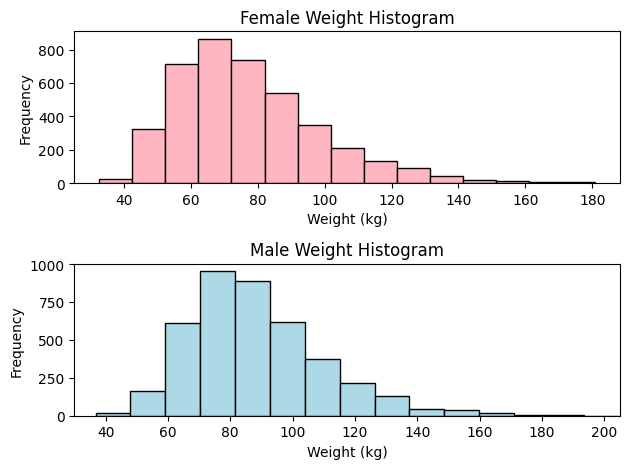

In [6]:
import matplotlib.pyplot as plt

plt.subplot(2,1,1)
plt.hist(x = female_weight, bins = 15, edgecolor = 'black', linewidth = 1, color="lightpink")
plt.title("Female Weight Histogram")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.subplot(2,1,2)
plt.hist(x = male_weight, bins = 15, edgecolor = 'black', linewidth = 1, color="lightblue")
plt.title("Male Weight Histogram")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.xlim(30,205)
plt.tight_layout()
plt.show()

### Visual Distribution Analysis
* **Shape**: Both distributions are unimodal and distinctly right-skewed (positively skewed), showing a long tail stretching toward the higher weight values.
* **Central Tendency & Shift**: The modal peak for females is located in the 60–70 kg region, whereas the peak for males is shifted further to the right, sitting in the 70–80 kg interval.
* **Range and Limits**: The shared $x$-axis ($30 \text{ to } 205 \text{ kg}$) effectively displays the entire dataset. It highlights that the extreme upper boundary of male weights extends further than the female equivalent.

### Boxplot Construction
We call `plt.boxplot()` to output a comparative box-and-whisker plot displaying both male and female weights side-by-side. This facilitates a clear visual comparison of median values, interquartile ranges, and outlier distributions.

## Section 4: Comparing Weights Using Boxplots

### Task Objective
This section addresses **Question 4**. We transition from histograms to boxplots (box-and-whisker plots) to compare the central tendencies, quartiles, and outliers of the male and female weight distributions side-by-side.

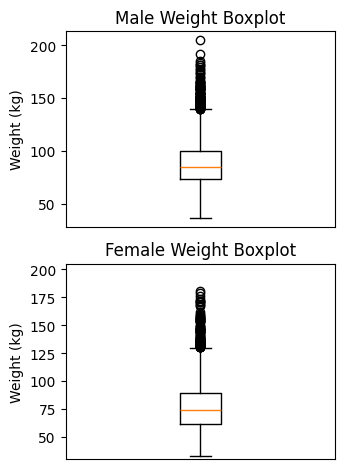

In [7]:
import matplotlib.pyplot as plt

plt.subplot(2, 2, 2)
plt.boxplot(x=male_weight)
plt.title("Male Weight Boxplot")
plt.ylabel("Weight (kg)")
plt.xticks([])

plt.subplot(2, 2, 4)
plt.boxplot(x=female_weight)
plt.title("Female Weight Boxplot")
plt.ylabel("Weight (kg)")
plt.xticks([])

plt.ylim(30, 205)
plt.tight_layout()
plt.show()


### Comparative Boxplot Representation
To facilitate a more direct comparison, we plot both cohorts within the same axes. This enables us to visually inspect the median values, interquartile ranges, and outlier thresholds together.

### Consolidated Visualization
We group both weight arrays into a single, multi-series data structure to plot the boxplots on a unified set of axes.

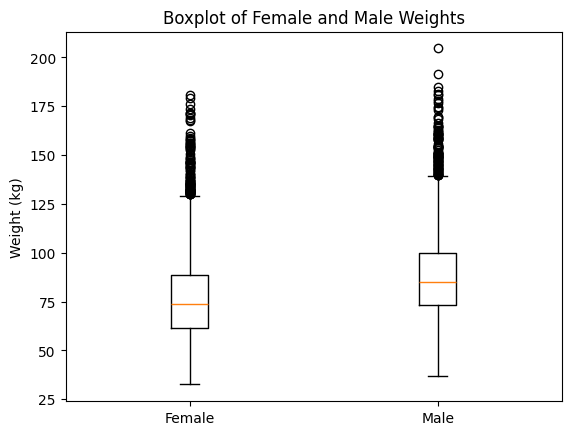

In [8]:
import matplotlib.pyplot as plt

plt.boxplot(x=[female_weight, male_weight])
plt.title("Boxplot of Female and Male Weights")
plt.ylabel("Weight (kg)")
plt.xticks([1, 2], ["Female", "Male"])
plt.show()

### Interpretation of Weight Boxplots
* **Median & Location Shift**: The median weight for males (indicated by the horizontal orange line around 85 kg) is visibly higher than the median weight for females (approx. 73.6 kg).
* **Interquartile Range (IQR)**: The middle 50% of the data (the height of the box) is highly comparable between both sexes, reflecting a similar spread of weights in the core population.
* **Outliers**: Both distributions exhibit significant right-tail outliers. Individual data points extend beyond the upper whisker ($1.5 \times \text{IQR}$ above the third quartile), demonstrating that both cohorts contain a portion of highly skewed, high-weight values.

### Quantitative Analysis of Distributions
We compute the statistical aggregates of weight across both cohorts, focusing on standard metrics of location, dispersion, and overall shape to provide an objective mathematical comparison.

## Section 5: Calculating and Interpreting Numerical Aggregates

### Task Objective
This section addresses **Question 5**. We move beyond visual heuristics and calculate precise, quantitative statistics for both weight variables. These metrics cover measures of location (mean, median), dispersion (standard deviation, variance, range, IQR), and shape (skewness, kurtosis).

In [9]:
import scipy.stats as stats
print("Computing the basic numerical aggregates of the male and female weights")
print("\n")
print("Measures of location: ")
print("Mean of Female Weights is:",female_weight.mean())
print("Mean of Male Weights is:",male_weight.mean())
print("Median of Female Weights is:",np.median(female_weight))
print("Median of Male Weights is:",np.median(male_weight))
print("\n")
print("Measures of dispersion: ")
print("Standard Deviation of Female Weights is:",female_weight.std())
print("Standard Deviation of Male Weights is:",male_weight.std())
print("Variance of Female Weights is:",female_weight.var())
print("Variance of Male Weights is:",male_weight.var())
print("Range of Female Weights is:",female_weight.max() - female_weight.min())
print("Range of Male Weights is:",male_weight.max() - male_weight.min())
print("The Inter-Quartile Range of Female Weights is:",np.quantile(female_weight, 0.75) - np.quantile(female_weight, 0.25))
print("The Inter-Quartile Range of Male Weights is:",np.quantile(male_weight, 0.75) - np.quantile(male_weight, 0.25))
print("\n")
print("Measures of Kurtosis: ")
male_kurtosis = np.round(stats.kurtosis(male_weight), 2)
female_kurtosis = np.round(stats.kurtosis(female_weight), 2)
print("Kurtosis in Male Weights:", male_kurtosis)
print("Kurtosis in Female Weights:", female_kurtosis)

Computing the basic numerical aggregates of the male and female weights


Measures of location: 
Mean of Female Weights is: 77.452964233219
Mean of Male Weights is: 88.36454300416565
Median of Female Weights is: 73.6
Median of Male Weights is: 85.0


Measures of dispersion: 
Standard Deviation of Female Weights is: 21.614859998204565
Standard Deviation of Male Weights is: 21.418936717962495
Variance of Female Weights is: 467.2021727419838
Variance of Male Weights is: 458.770850128082
Range of Female Weights is: 148.3
Range of Male Weights is: 167.8
The Inter-Quartile Range of Female Weights is: 27.099999999999994
The Inter-Quartile Range of Male Weights is: 26.5


Measures of Kurtosis: 
Kurtosis in Male Weights: 1.47
Kurtosis in Female Weights: 1.43


### Distribution Shape Visualization with Kernel Density Estimations (KDE)
To pair with the numerical outputs, we plot the overlapping distributions alongside their respective skewness values using Kernel Density Estimations (KDE).

Skewness in Data: 
Skewness in Male Data is: 0.98
Skewness in Female Data is: 1.04


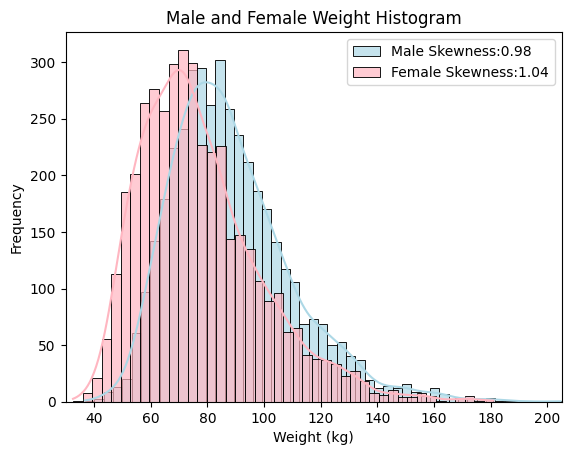

In [10]:
import scipy.stats as stats
import seaborn as sns
print("Skewness in Data: ")

male_skew = np.round(stats.skew(male_weight), 2)
print("Skewness in Male Data is:",male_skew)

female_skew = np.round(stats.skew(female_weight), 2)
print("Skewness in Female Data is:",female_skew)

sns.histplot(data=male_weight, kde=True, color="lightblue", alpha=0.7, label=f"Male Skewness:{male_skew}")
sns.histplot(data=female_weight, kde=True, color="lightpink", alpha=0.7, label=f"Female Skewness:{female_skew}")
plt.title("Male and Female Weight Histogram")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(30,205)
plt.legend()
plt.show()

### Comprehensive Statistical Interpretation

#### 1. Measures of Location
* **Mean**: The mean weight for males ($88.36 \text{ kg}$) is $10.91 \text{ kg}$ higher than the mean weight for females ($77.45 \text{ kg}$).
* **Median**: The median weight for males ($85.0 \text{ kg}$) is $11.4 \text{ kg}$ higher than the median weight for females ($73.6 \text{ kg}$).
* **Analysis**: Because the mean is greater than the median in both cohorts (Males: $88.36 > 85.0$; Females: $77.45 > 73.6$), both datasets are mathematically confirmed to be positively (right) skewed.

#### 2. Measures of Dispersion
* **Standard Deviation & Variance**: Surprisingly, the dispersion metrics are nearly identical. The standard deviation is slightly higher in females ($21.61 \text{ kg}$) than in males ($21.42 \text{ kg}$). This pattern is also reflected in their variances ($467.20 \text{ kg}^2$ vs. $458.77 \text{ kg}^2$).
* **Interquartile Range (IQR)**: The middle 50% spread is slightly wider for females ($27.10 \text{ kg}$) compared to males ($26.50 \text{ kg}$).
* **Overall Range**: Males exhibit a wider overall range ($167.80 \text{ kg}$) compared to females ($148.30 \text{ kg}$), driven by the extreme values at the upper end of the distribution.

#### 3. Measures of Shape
* **Skewness**: The female distribution exhibits a skewness of $1.04$, and the male distribution exhibits a skewness of $0.98$. Both values exceed $0.5$, indicating moderate to high positive skewness.
* **Kurtosis**: The calculated excess kurtosis values (Males: $1.47$, Females: $1.43$) are positive, indicating leptokurtic distributions with heavier tails and a higher concentration of outliers compared to a standard normal distribution.

### BMI Column Appending
We compute the Body Mass Index (BMI) for each female participant and append these values as the eighth column (index 7) in the female dataset.

## Section 6: Calculating and Adding BMI to the Female Dataset

### Task Objective
This section addresses **Question 6**. Body Mass Index (BMI) is calculated for the female cohort using the standard formula:

$$\text{BMI} = \frac{\text{Weight (kg)}}{\left(\frac{\text{Height (cm)}}{100}\right)^2}$$

This calculated array is appended to the `female_data` matrix as its eighth column (index 7).

In [11]:
bmi_1d_array = np.array(np.round((female_data[:,0] / (female_data[:,1] / 100) ** 2), 1))
female_data = np.column_stack((female_data, bmi_1d_array))#If we run this again and again then it will add to the matric so i comment it for now after adding the new BMI columns
print(female_data)

[[ 97.1 160.2  34.7 ... 126.1 117.9  37.8]
 [ 91.1 152.7  33.5 ... 125.5 103.1  39.1]
 [ 73.  161.2  37.4 ... 106.2  92.   28.1]
 ...
 [ 73.  159.6  36.2 ... 104.6  99.3  28.7]
 [ 78.6 168.5  38.1 ... 102.4  98.5  27.7]
 [ 82.8 147.8  34.8 ... 121.4 110.   37.9]]


### Alternative Column Engineering Implementation (Pandas)
For reference, the same operation can be performed using Pandas before converting the data back into a NumPy array structure.

In [12]:
## -> Using Pandas

# data_female = pd.read_csv("female_dataset.csv")
# data_female['BMI'] = np.round((data_female["BMXWT"] / (data_female["BMXHT"] / 100) ** 2), 1)
# female_data = np.array(data_female)

# print("New BMI Column is added to the array")
# print(female_data)

## Section 7: Standardising the Female Dataset

### Task Objective
This section addresses **Question 7**. To enable direct, unit-independent comparisons across anthropometric features, we transform the raw metrics of the female cohort into $z$-scores:

$$z = \frac{x - \mu}{\sigma}$$

This standardisation centres each variable around a mean of 0 with a standard deviation of 1.

### Dataset Standardisation
We construct a new matrix named `zfemale_data` which contains the fully standardised z-scores for every column in the original female matrix.

In [13]:
zfemale_data = stats.zscore(female_data)
print("Created new matrix zfemale being a version of the female dataset with all its columns standardised: \n")
print(zfemale_data)

Created new matrix zfemale being a version of the female dataset with all its columns standardised: 

[[ 9.14295084e-01  8.95037880e-03 -5.67394633e-01 ...  1.08316157e+00
   1.11578462e+00  9.92545031e-01]
 [ 6.35775985e-01 -1.05306843e+00 -1.07893145e+00 ...  1.04475528e+00
   2.65088995e-01  1.16018565e+00]
 [-2.04423297e-01  1.50552886e-01  5.83563204e-01 ... -1.90646881e-01
  -3.72932724e-01 -2.58311918e-01]
 ...
 [-2.04423297e-01 -7.60111255e-02  7.20263874e-02 ... -2.93063641e-01
   4.66671455e-02 -1.80939323e-01]
 [ 5.55278621e-02  1.18425119e+00  8.81959680e-01 ... -4.33886685e-01
   6.83598104e-04 -3.09893648e-01]
 [ 2.50491231e-01 -1.74692071e+00 -5.24766565e-01 ...  7.82312335e-01
   6.61697091e-01  1.00544046e+00]]


### Extraction of Standardised Feature Arrays
We extract individual standardized arrays from `zfemale_data` to map them directly to our target variables of interest:
* Weight ($z$-column 0)
* Height ($z$-column 1)
* Hip Circumference ($z$-column 5)
* Waist Circumference ($z$-column 6)
* BMI ($z$-column 7).

In [14]:
weight = zfemale_data[:, 0]
print(weight)
height = zfemale_data[:, 1]
print(height)
hip_cir = zfemale_data[:, 5]
print(hip_cir)
waist_cir = zfemale_data[:, 6]
print(waist_cir)
bmi = zfemale_data[:, 7]
print(bmi)

[ 0.91429508  0.63577599 -0.2044233  ... -0.2044233   0.05552786
  0.25049123]
[ 0.00895038 -1.05306843  0.15055289 ... -0.07601113  1.18425119
 -1.74692071]
[ 1.08316157  1.04475528 -0.19064688 ... -0.29306364 -0.43388669
  0.78231234]
[ 1.11578462e+00  2.65088995e-01 -3.72932724e-01 ...  4.66671455e-02
  6.83598104e-04  6.61697091e-01]
[ 0.99254503  1.16018565 -0.25831192 ... -0.18093932 -0.30989365
  1.00544046]


## Section 8: Analysing Standardised Body Measurements Using Pairplots and Correlations

### Task Objective
This section addresses **Question 8**. We examine the relationships between five key standardized metrics—Weight, Height, Hip Circumference, Waist Circumference, and BMI—using a scatterplot matrix (pairplot) along with Pearson's and Spearman's correlation matrices.

### Visual and Linear Correlation Profiling
We construct a pairwise scatterplot matrix (pairplot) of the standardised features and compute both Pearson's and Spearman's correlation matrices to interpret the strength and direction of these linear and rank-based relationships.

### Pairplot Construction DataFrame
We construct a temporary pandas DataFrame called `new_zfemale_data` to label the standardized columns correctly for visualization and analysis.

In [15]:
new_zfemale_data = pd.DataFrame({"Weight": weight, "Height": height, "Hip Circumference": hip_cir, "Waist Circumference": waist_cir, "BMI": bmi})
print(new_zfemale_data)

        Weight    Height  Hip Circumference  Waist Circumference       BMI
0     0.914295  0.008950           1.083162             1.115785  0.992545
1     0.635776 -1.053068           1.044755             0.265089  1.160186
2    -0.204423  0.150553          -0.190647            -0.372933 -0.258312
3    -0.728968 -0.387537          -0.523501            -0.459152 -0.670966
4    -1.021413 -0.784024          -1.067590            -1.453546 -0.890188
...        ...       ...                ...                  ...       ...
4216 -0.492226 -0.444178          -0.344272            -0.344193 -0.387266
4217  1.833408  1.028488           1.230386             1.236491  1.495467
4218 -0.204423 -0.076011          -0.293064             0.046667 -0.180939
4219  0.055528  1.184251          -0.433887             0.000684 -0.309894
4220  0.250491 -1.746921           0.782312             0.661697  1.005440

[4221 rows x 5 columns]


### Pairplot Visualization
We generate the pairwise scatterplots and marginal histograms to visually inspect the relationships and distribution shapes of the standardized variables.

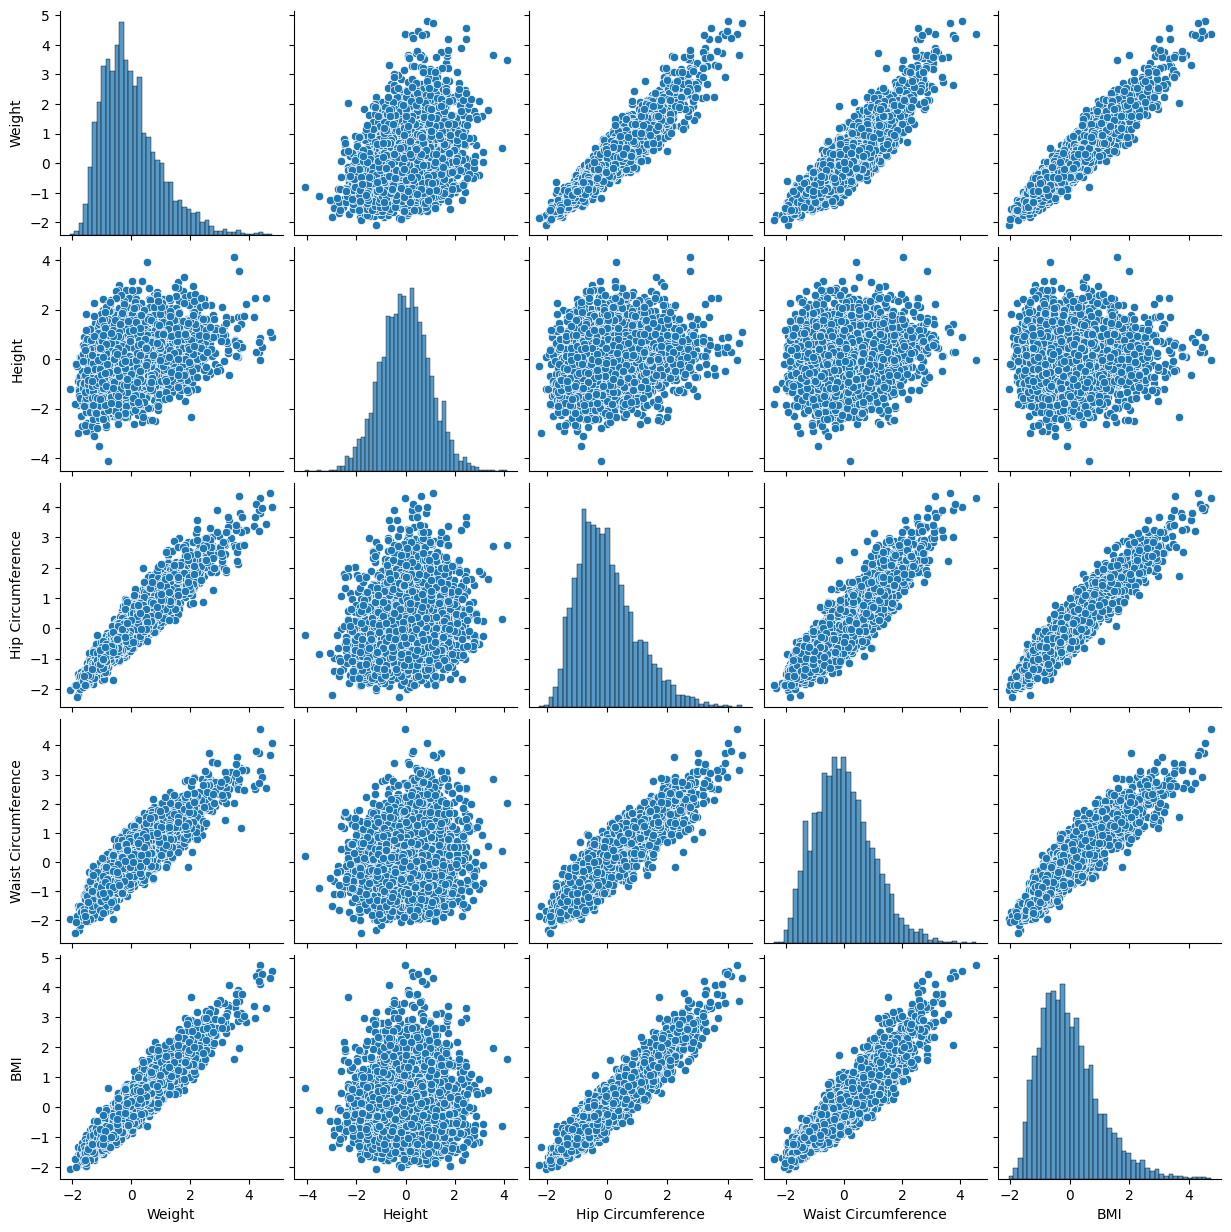

In [16]:
sns.pairplot(data = new_zfemale_data)
plt.show()

### Quantitative Correlation Matrices
To confirm our visual observations, we calculate both Pearson's linear correlation coefficients and Spearman's rank-based correlation coefficients.

In [17]:
pearson_matrix = new_zfemale_data.corr(method='pearson')

spearman_matrix = new_zfemale_data.corr(method='spearman')

pd.set_option('display.expand_frame_repr', False) ## Asked AI to find how to force pandas to never wrap columns horizontally

print("--- Whole new_zfemale_data Pearson's Correlation ---")
print(pearson_matrix)

print("\n--- Whole new_zfemale_data Spearman's Correlation ---")
print(spearman_matrix)

--- Whole new_zfemale_data Pearson's Correlation ---
                       Weight    Height  Hip Circumference  Waist Circumference       BMI
Weight               1.000000  0.345496           0.946553             0.904550  0.945864
Height               0.345496  1.000000           0.202895             0.126547  0.032982
Hip Circumference    0.946553  0.202895           1.000000             0.897407  0.944179
Waist Circumference  0.904550  0.126547           0.897407             1.000000  0.921203
BMI                  0.945864  0.032982           0.944179             0.921203  1.000000

--- Whole new_zfemale_data Spearman's Correlation ---
                       Weight    Height  Hip Circumference  Waist Circumference       BMI
Weight               1.000000  0.338860           0.946634             0.900169  0.937929
Height               0.338860  1.000000           0.205405             0.108587  0.019767
Hip Circumference    0.946634  0.205405           1.000000             0.888037  0

### Interpretation of Relationships and Correlations

#### 1. Strong Linear and Monotonic Relationships
* **Weight, Hip Circumference, Waist Circumference, and BMI**: These four variables show exceptionally strong positive relationships. All pairwise correlation coefficients exceed $0.89$ in both matrices.
  * **Weight vs. BMI**: Shows a highly linear relationship (Pearson $r = 0.946$, Spearman $\rho = 0.938$). This suggests that body weight is the primary driver of variation in BMI within this female cohort.
  * **Hip Circumference vs. Weight**: Exhibits a strong linear relationship ($r = 0.947$, $\rho = 0.947$). This is expected, as larger skeletal and soft tissue circumferences naturally contribute to overall body mass.
  * **Waist Circumference vs. BMI**: Shows a strong positive correlation ($r = 0.921$, $\rho = 0.923$). This indicates that waist circumference increases closely in tandem with overall BMI.

#### 2. Weak Linear and Monotonic Relationships
* **Height vs. Weight**: Exhibits a weak positive correlation ($r = 0.345$, $\rho = 0.339$). This shows that while taller individuals tend to be heavier, height alone explains only a small portion of the variation in weight.
* **Height vs. BMI**: There is virtually no correlation between height and BMI ($r = 0.033$, $\rho = 0.020$). This demonstrates that standardising weight by squared height successfully decouples BMI from the participant's height.
* **Height vs. Circumferences**: Height shows a weak positive relationship with hip circumference ($r = 0.203$) and an even weaker relationship with waist circumference ($r = 0.127$).

#### 3. Pearson vs. Spearman Comparison
* The Pearson and Spearman coefficients are remarkably similar across all pairs. This consistency indicates that the relationships are largely linear and are not heavily distorted by extreme outliers or non-linear, monotonic patterns.

### Waist-to-Height and Waist-to-Hip Ratio Calculations
We compute the waist-to-height ratio (WHtR) and the waist-to-hip ratio (WHR) for both male and female cohorts, extending both datasets with these diagnostic columns.

## Section 9: Calculating Waist-to-Height and Waist-to-Hip Ratios

### Task Objective
This section addresses **Question 9**. We calculate two body proportion metrics—the waist-to-height ratio (WHtR) and the waist-to-hip ratio (WHR)—for both the male and female cohorts. These ratios are then appended to their respective primary matrices.

In [18]:
female_ratio_1 = np.array(np.round(female_data[:, 6] / female_data[:, 1], 2))
female_ratio_2 = np.array(np.round(female_data[:, 6] / female_data[:, 5], 2))

male_ratio_1 = np.array(np.round(male_data[:, 6] / male_data[:, 1], 2))
male_ratio_2 = np.array(np.round(male_data[:, 6] / male_data[:, 5], 2))

print("Female Waist Circumference to Height Ratio: \n", female_ratio_1)
print("Female Waist Circumference to Hip Circumference Ratio: \n", female_ratio_2)
print("Male Waist Circumference to Height Ratio: \n", male_ratio_1)
print("Male Waist Circumference to Hip Circumference Ratio: \n", male_ratio_2)

female_data = np.column_stack((female_data, female_ratio_1, female_ratio_2)) #If we run this again and again then it will add to the matric so i comment it for now after adding the two new ratio columns
male_data = np.column_stack((male_data, male_ratio_1, male_ratio_2))

print("\nUpdated female and male matrics are: ")
print(female_data)
print(male_data)

print("\nFemale data must have one column more bacuase of BMI where as there are only 9 column in both dataset if we not considered BMI in the female data: ")
print(female_data.shape)
print(male_data.shape)

Female Waist Circumference to Height Ratio: 
 [0.74 0.68 0.57 ... 0.62 0.58 0.74]
Female Waist Circumference to Hip Circumference Ratio: 
 [0.93 0.82 0.87 ... 0.95 0.96 0.91]
Male Waist Circumference to Height Ratio: 
 [0.66 0.47 0.59 ... 0.68 0.55 0.52]
Male Waist Circumference to Hip Circumference Ratio: 
 [1.11 0.92 1.02 ... 0.97 0.97 0.96]

Updated female and male matrics are: 
[[ 97.1  160.2   34.7  ...  37.8    0.74   0.93]
 [ 91.1  152.7   33.5  ...  39.1    0.68   0.82]
 [ 73.   161.2   37.4  ...  28.1    0.57   0.87]
 ...
 [ 73.   159.6   36.2  ...  28.7    0.62   0.95]
 [ 78.6  168.5   38.1  ...  27.7    0.58   0.96]
 [ 82.8  147.8   34.8  ...  37.9    0.74   0.91]]
[[ 98.8  182.3   42.   ... 120.4    0.66   1.11]
 [ 74.3  184.2   41.1  ...  86.8    0.47   0.92]
 [103.7  185.3   47.   ... 109.6    0.59   1.02]
 ...
 [108.8  168.7   38.6  ... 114.7    0.68   0.97]
 [ 79.5  176.4   39.5  ...  97.1    0.55   0.97]
 [ 59.7  167.5   40.3  ...  86.9    0.52   0.96]]

Female data mu

## Section 10: Comparing Body-Ratio Distributions Using Boxplots

### Task Objective
This section addresses **Question 10**. We visualize the distributions of the two newly created body ratios (waist-to-height and waist-to-hip) for both male and female cohorts side-by-side on a single boxplot.

### Visualizing Ratio Boxplots
We draw a boxplot containing four side-by-side boxes to visually compare the distribution of the two body ratios across both sexes.

### Visual Analysis of the Ratio Distributions
* **Waist-to-Height Ratio (WHtR)**:
  * Both the male and female distributions are very similar. The median values are close, hovering around $0.58$ for males and $0.61$ for females.
  * This suggests that, on average, waist circumference is about 60% of standing height for both cohorts in this sample.
* **Waist-to-Hip Ratio (WHR)**:
  * There is a distinct, non-overlapping difference between the sexes. The male distribution (median $\approx 0.98$) is shifted noticeably higher than the female distribution (median $\approx 0.90$).
  * This reflects a biological difference in fat distribution. Males tend to accumulate adipose tissue primarily around the abdomen (android fat pattern), whereas females tend to accumulate more tissue around the hips and thighs (gynoid fat pattern).

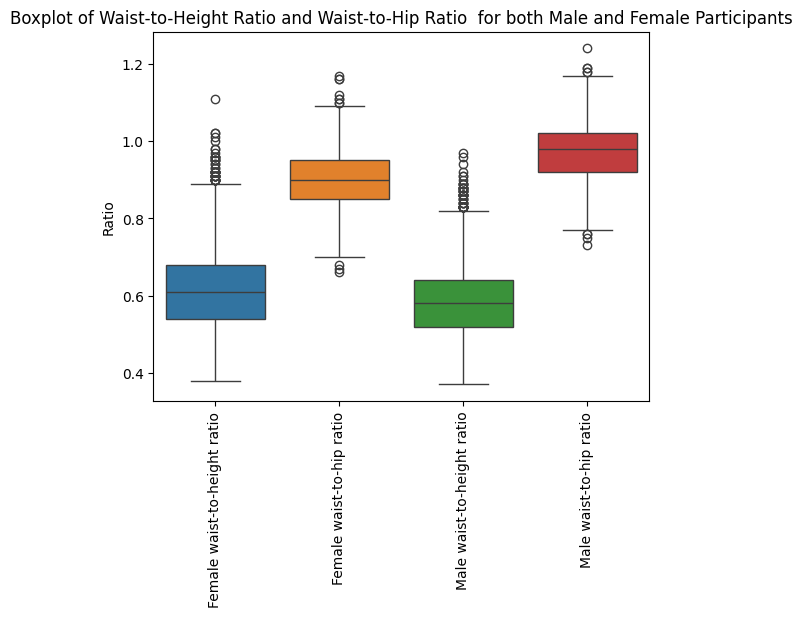

In [19]:
sns.boxplot(data=[female_ratio_1, female_ratio_2, male_ratio_1, male_ratio_2])
plt.xticks([0, 1, 2, 3], ["Female waist-to-height ratio", "Female waist-to-hip ratio", "Male waist-to-height ratio", "Male waist-to-hip ratio"], rotation=90)
plt.title("Boxplot of Waist-to-Height Ratio and Waist-to-Hip Ratio  for both Male and Female Participants")
plt.ylabel("Ratio")
plt.show()

## Section 11: Advantages and Disadvantages of Anthropometric Indexes

This section addresses **Question 11**. We compare the practical utility and limitations of Body Mass Index (BMI), Waist-to-Height Ratio (WHtR), and Waist-to-Hip Ratio (WHR) based on our analyses and established literature.

### Anthropometric Metrics Evaluation
We list and evaluate the key clinical advantages and disadvantages of BMI, waist-to-height ratio, and waist-to-hip ratio.

*Please refer to the following cell for the detailed comparative analysis of these three indexes.*

## 1. BMI (Body Mass Index)

Advantages:

- Easy to calculate using weight and height.
- Requires only two measurements.
- Useful for classifying people as underweight, normal weight, overweight, or obese using standard adult BMI categories.

Disadvantages:

- Does not distinguish between muscle and fat.
- Does not show where fat is stored in the body.
- May not accurately reflect body composition in every individual.

## 2. Waist-to-Height Ratio (WHtR)

Advantages:

- Easy to calculate using waist circumference and height.
- Helps estimate abdominal fat relative to height.
- Can help identify potential health risks associated with excess abdominal fat.

Disadvantages:

- Waist and height measurements must be taken correctly.
- Does not directly measure body fat.
- May not be equally suitable for every age group or population.

## 3. Waist-to-Hip Ratio (WHR)

Advantages:

- Easy to calculate using waist and hip circumferences.
- Helps show how body fat is distributed around the waist compared with the hips.
- Can help assess potential health risks associated with abdominal fat distribution.

Disadvantages:

- Requires two circumference measurements, which can introduce measurement errors.
- Does not directly measure total body fat.
- Results may be affected by differences in body shape and hip size.

### Conclusion

BMI is a simple measure based on weight and height, while waist-to-height ratio and waist-to-hip ratio provide additional information about abdominal fat distribution. Using these measures together can give a more complete picture than relying on BMI alone, although none of them directly measures body fat or provides a complete assessment of health.

## Section 12: Examining Extreme Outliers (Lowest vs. Highest BMI Females)

### Task Objective
This section addresses **Question 12**. We identify the five female participants with the lowest BMIs and the five with the highest BMIs to examine how their standardized body measurements differ at these extremes.

In [20]:
print("The 5 females with the lowest BMI:")
lowest_5_bmi = np.argsort(female_data[:, 7])[:5]
print(zfemale_data[lowest_5_bmi])

print("\nThe 5 females with the highest BMI:")
highest_5_bmi = np.argsort(female_data[:, 7])[-5:][::-1]
print(zfemale_data[highest_5_bmi])

The 5 females with the lowest BMI:
[[-2.07978523 -1.22299143 -1.5478402  -1.16905675 -2.1947611  -2.0405496
  -1.94212128 -2.05077703]
 [-1.88017988 -0.18929313 -1.71835247  0.38637892 -2.4443617  -1.85491922
  -2.05708015 -1.9991953 ]
 [-1.53667299  1.80730222  0.62619127  0.5730312  -2.26607556 -1.6756899
  -1.7064556  -1.97340444]
 [-1.843044   -0.26009438 -0.22637009  0.51081377 -2.30173278 -2.25178417
  -1.85590213 -1.94761357]
 [-1.61094475  0.88688592 -0.09848588  0.47970506 -2.21258971 -1.82931504
  -1.71220354 -1.89603184]]

The 5 females with the highest BMI:
[[ 4.36328993 -0.03353037 -0.05585782 -0.17357792  2.77942222  4.31569054
   4.57029862  4.75801131]
 [ 4.8042785   0.88688592  2.11817365  1.81737973  3.77782461  4.02124236
   4.08172343  4.53878896]
 [ 4.34936397  0.27799514  2.84285081  1.94181459  4.36616887  3.9188256
   3.75409065  4.51299809]
 [ 4.45612963  0.50455915  1.69189297 -1.13794804  3.34993787  3.98283607
   2.90339503  4.46141637]
 [ 4.2472403   0.2921

### Detailed Analysis of Extreme Cohorts

#### 1. Low-BMI Group (The 5 Females with the Lowest BMIs)
* **Standardized BMIs**: These individuals fall approximately $1.90$ to $2.05$ standard deviations below the cohort mean ($z$-values range from $-1.89$ to $-2.05$).
* **Weight, Waist, and Hip Circumferences**:
  * Consistent with their low BMIs, all standardized metrics for weight, waist circumference, and hip circumference are extremely low. Their $z$-scores generally range between $-1.5$ and $-2.4$.
* **Height**:
  * Unlike the other metrics, height $z$-scores vary widely, ranging from $-1.22$ (shorter than average) to $+1.80$ (significantly taller than average).
  * This demonstrates that a very low BMI can occur at any height, as BMI is standardized for height.

#### 2. High-BMI Group (The 5 Females with the Highest BMIs)
* **Standardized BMIs**: These individuals exhibit extremely high BMIs, falling between $4.39$ and $4.76$ standard deviations above the mean.
* **Weight, Waist, and Hip Circumferences**:
  * Their standardized weights ($z \approx 4.24 \text{ to } 4.80$), waist circumferences ($z \approx 2.90 \text{ to } 4.57$), and hip circumferences ($z \approx 3.91 \text{ to } 4.31$) are all extremely high.
  * These extreme values correspond directly to the long right tail observed in our earlier histograms.
* **Height**:
  * The height $z$-scores for this group are close to average (ranging from $-0.03$ to $+0.88$).
  * This indicates that these exceptionally high BMIs are driven primarily by very high body weight and fat distribution, rather than unusual variations in height.

---
**Report Status**: Completed. Ready for review by the Project Manager.